<div align="center">
 
### Lab 03 | Neural Coding: From Spikes to Information

---

**Programming Environment:** Python  
**Libraries:** NumPy • Matplotlib  

</div>

---

#### Learning Outcomes

By completing this lab, you will be able to:

---
### 
1.	Explain the difference between rate coding and temporal coding
2.  Simulate spike trains using probabilistic models
3.  Understand how refractory periods limit firing rates
4.  Analyze inter-spike intervals (ISI)
5.  Demonstrate how population size improves decoding accuracy
6.  Interpret how biological constraints shape neural information processing


### Part A — Spike trains as a code (Poisson model)
Goal: Show that spikes are discrete events and coding often happens in rate or timing.

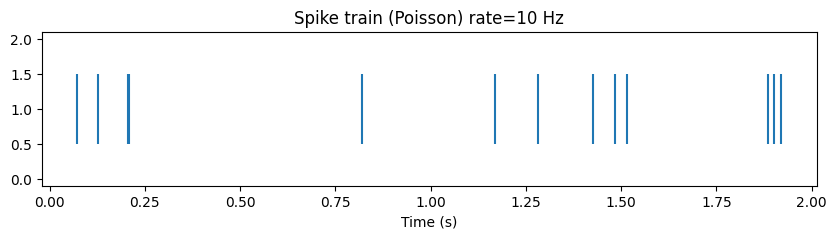

Estimated rate (Hz): 6.5


In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

T = 2.0          # seconds
dt = 0.001       # 1 ms
t = np.arange(0, T, dt)

def poisson_spikes(rate_hz, t, dt):
    p = rate_hz * dt
    return (np.random.rand(len(t)) < p).astype(int)

rate = 10  # Hz
spikes = poisson_spikes(rate, t, dt)

plt.figure(figsize=(10,2))
plt.eventplot(t[spikes==1])
plt.title(f"Spike train (Poisson) rate={rate} Hz")
plt.xlabel("Time (s)")
plt.show()

print("Estimated rate (Hz):", spikes.sum()/T)

True rate =  5 Hz  ->  estimated rate = 4.50 Hz
True rate = 20 Hz  ->  estimated rate = 18.00 Hz
True rate = 50 Hz  ->  estimated rate = 48.00 Hz


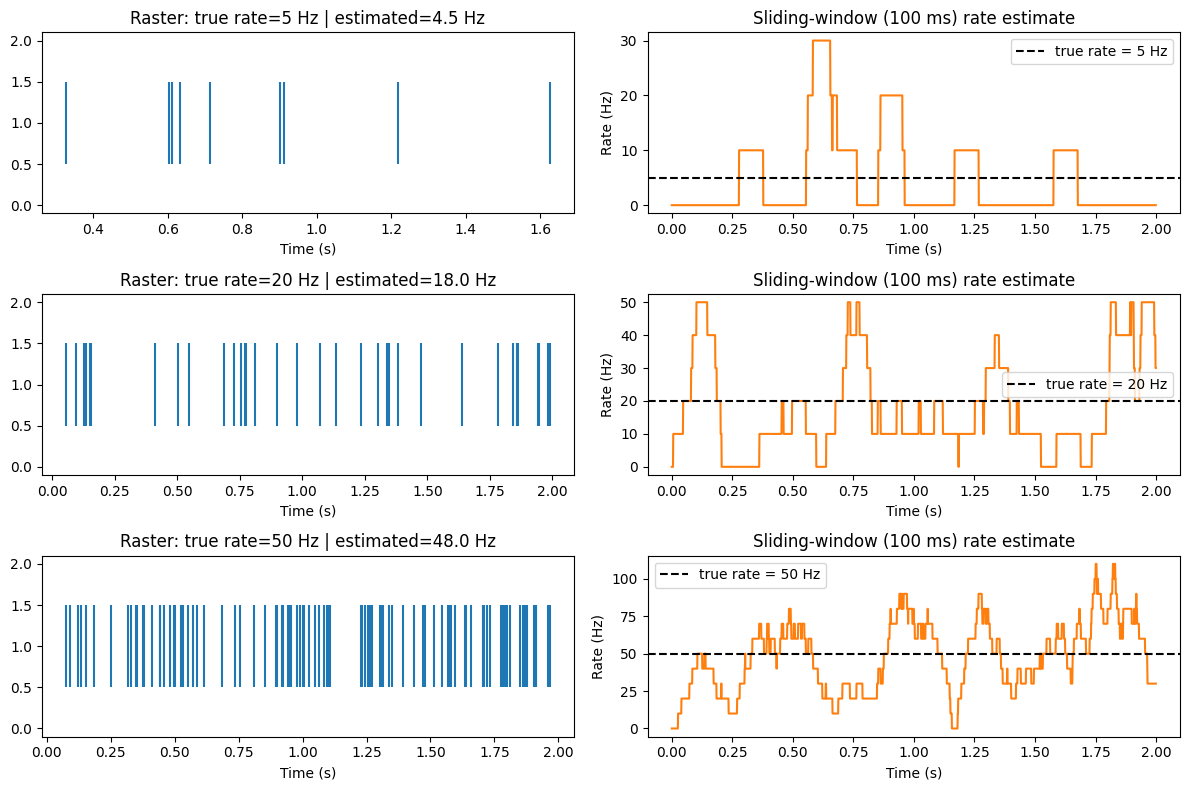

In [2]:
# TODO 1:
# Change rate = 5, 20, 50 and observe the raster + estimated rate.
# Add a rate estimator using a sliding window (simple moving average).

def sliding_window_rate(spikes, dt, window_s=0.1):
    """Estimate instantaneous firing rate (Hz) with a simple moving average.

    The spike train (0/1 per bin) is averaged over a window of length
    window_s and divided by dt to convert spike probability per bin
    into a rate in Hz.
    """
    win_bins = int(window_s / dt)
    kernel = np.ones(win_bins) / win_bins
    return np.convolve(spikes, kernel, mode="same") / dt

rates_to_test = [5, 20, 50]

fig, axes = plt.subplots(len(rates_to_test), 2, figsize=(12, 8))
for row, r in enumerate(rates_to_test):
    sp = poisson_spikes(r, t, dt)
    est_total = sp.sum() / T
    est_sliding = sliding_window_rate(sp, dt, window_s=0.1)

    # Raster
    axes[row, 0].eventplot(t[sp == 1])
    axes[row, 0].set_title(f"Raster: true rate={r} Hz | estimated={est_total:.1f} Hz")
    axes[row, 0].set_xlabel("Time (s)")

    # Sliding-window rate estimate
    axes[row, 1].plot(t, est_sliding, color="tab:orange")
    axes[row, 1].axhline(r, color="k", ls="--", label=f"true rate = {r} Hz")
    axes[row, 1].set_title(f"Sliding-window (100 ms) rate estimate")
    axes[row, 1].set_xlabel("Time (s)")
    axes[row, 1].set_ylabel("Rate (Hz)")
    axes[row, 1].legend()

    print(f"True rate = {r:2d} Hz  ->  estimated rate = {est_total:.2f} Hz")

plt.tight_layout()
plt.show()

**Observation (TODO 1):** As the true rate increases from 5 → 20 → 50 Hz, the raster becomes denser and the estimated rate (spike count / duration) tracks the true rate closely. The 100 ms sliding-window (moving-average) estimator fluctuates around the true rate — the fluctuations are relatively larger at low rates because fewer spikes fall inside each window (Poisson variability).

### Part B — Refractory period (biophysical constraint)
Goal : Show that biology imposes limits on maximum firing rate.

In [3]:
def poisson_spikes_with_refractory(rate_hz, t, dt, refrac_s=0.01):
    p = rate_hz * dt
    spikes = np.zeros(len(t), dtype=int)
    last_spike_t = -np.inf
    for i, ti in enumerate(t):
        if (ti - last_spike_t) >= refrac_s:
            if np.random.rand() < p:
                spikes[i] = 1
                last_spike_t = ti
    return spikes

rate = 80
sp_no_ref = poisson_spikes(rate, t, dt)
sp_ref = poisson_spikes_with_refractory(rate, t, dt, refrac_s=0.01)

print("No ref rate:", sp_no_ref.sum()/T)
print("With ref rate:", sp_ref.sum()/T)

No ref rate: 77.0
With ref rate: 45.0


refrac =    2 ms -> achieved rate = 73.5 Hz (theoretical max = 500 Hz)
refrac =    5 ms -> achieved rate = 62.0 Hz (theoretical max = 200 Hz)
refrac =   10 ms -> achieved rate = 47.0 Hz (theoretical max = 100 Hz)


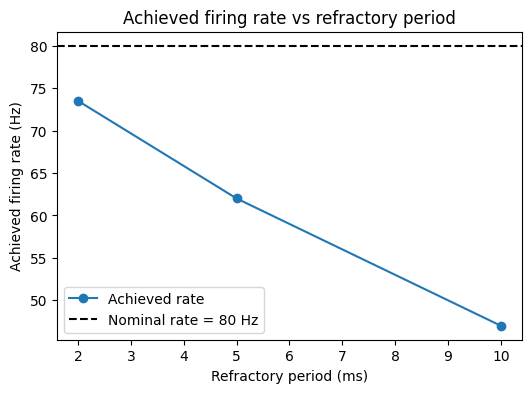

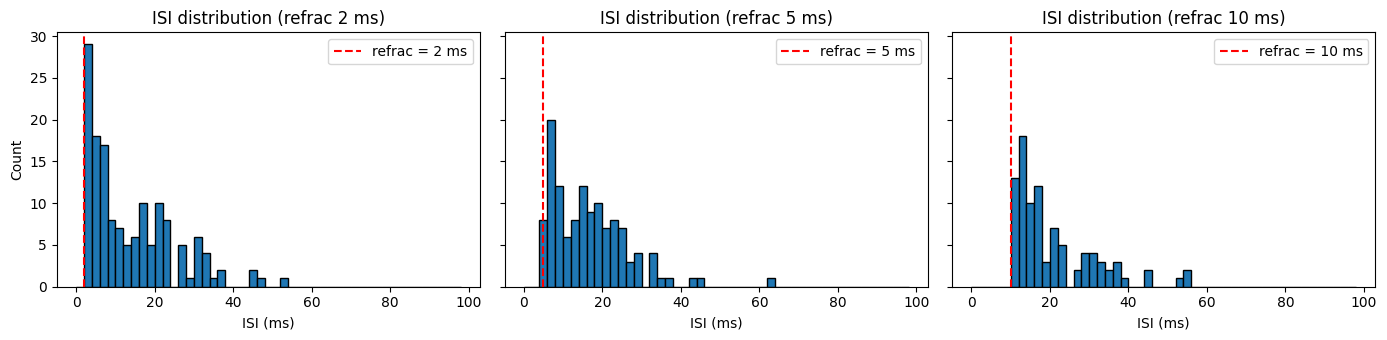

In [4]:
# TODO 2:
# Vary refrac_s (2ms, 5ms, 10ms) and plot achieved firing rate vs refractory.
# Compute ISI (inter-spike interval) distribution and show the "gap" caused by refractory.
# What happens when refractory increases?

rate = 80  # Hz (high rate so the refractory limit is visible)
refrac_list = [0.002, 0.005, 0.010]  # 2 ms, 5 ms, 10 ms

# --- Achieved firing rate vs refractory period ---
achieved = []
spike_trains = {}
for rf in refrac_list:
    sp = poisson_spikes_with_refractory(rate, t, dt, refrac_s=rf)
    spike_trains[rf] = sp
    achieved.append(sp.sum() / T)
    print(f"refrac = {rf*1000:4.0f} ms -> achieved rate = {sp.sum()/T:.1f} Hz "
          f"(theoretical max = {1/rf:.0f} Hz)")

plt.figure(figsize=(6, 4))
plt.plot(np.array(refrac_list) * 1000, achieved, "o-", label="Achieved rate")
plt.axhline(rate, color="k", ls="--", label=f"Nominal rate = {rate} Hz")
plt.xlabel("Refractory period (ms)")
plt.ylabel("Achieved firing rate (Hz)")
plt.title("Achieved firing rate vs refractory period")
plt.legend()
plt.show()

# --- ISI (inter-spike interval) code ---
def compute_isi(spikes, t):
    """Return inter-spike intervals (in s) from a binary spike train."""
    spike_times = t[spikes == 1]
    return np.diff(spike_times)

fig, axes = plt.subplots(1, len(refrac_list), figsize=(14, 3.5), sharey=True)
for ax, rf in zip(axes, refrac_list):
    isi = compute_isi(spike_trains[rf], t)
    ax.hist(isi * 1000, bins=np.arange(0, 100, 2), color="tab:blue", edgecolor="k")
    ax.axvline(rf * 1000, color="r", ls="--", label=f"refrac = {rf*1000:.0f} ms")
    ax.set_xlabel("ISI (ms)")
    ax.set_title(f"ISI distribution (refrac {rf*1000:.0f} ms)")
    ax.legend()
axes[0].set_ylabel("Count")
plt.tight_layout()
plt.show()

**Observation (TODO 2):** The ISI histograms show a clear "gap": no interval shorter than the refractory period can occur (red dashed line), whereas a pure Poisson process would have many very short ISIs. As the refractory period increases (2 → 5 → 10 ms), the gap widens, the achieved firing rate drops further below the nominal 80 Hz, and the maximum possible rate is capped at roughly 1/refrac_s (e.g. ~100 Hz for 10 ms). The spike train also becomes more regular (less Poisson-like) because the refractory period removes the short intervals.

### Part C — Rate coding experiment (stimulus intensity → firing rate)

Goal: Show “intensity” is encoded by spike rate, not spike amplitude.


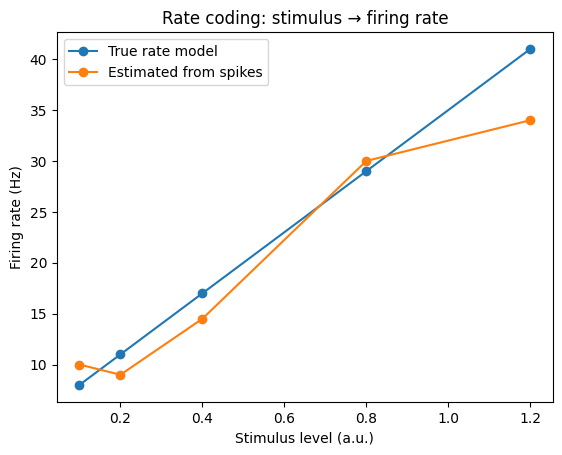

In [5]:
stim_levels = np.array([0.1, 0.2, 0.4, 0.8, 1.2])  # arbitrary stimulus
base = 5
gain = 30

rates = base + gain*stim_levels  # simple encoding model

estimated = []
for r in rates:
    sp = poisson_spikes(r, t, dt)
    estimated.append(sp.sum()/T)

plt.figure()
plt.plot(stim_levels, rates, marker='o', label="True rate model")
plt.plot(stim_levels, estimated, marker='o', label="Estimated from spikes")
plt.xlabel("Stimulus level (a.u.)")
plt.ylabel("Firing rate (Hz)")
plt.title("Rate coding: stimulus → firing rate")
plt.legend()
plt.show()

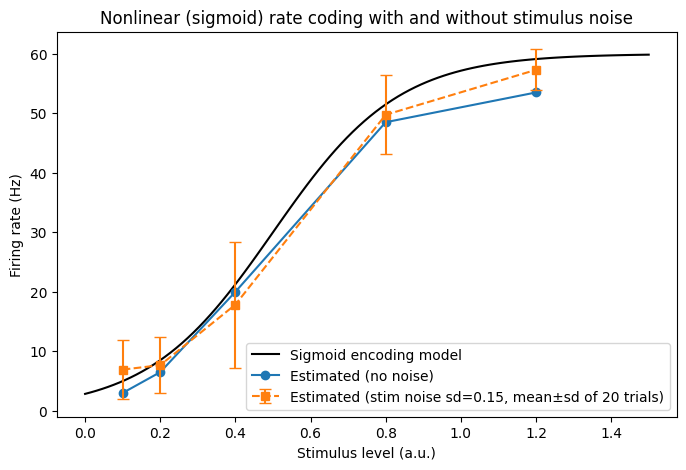

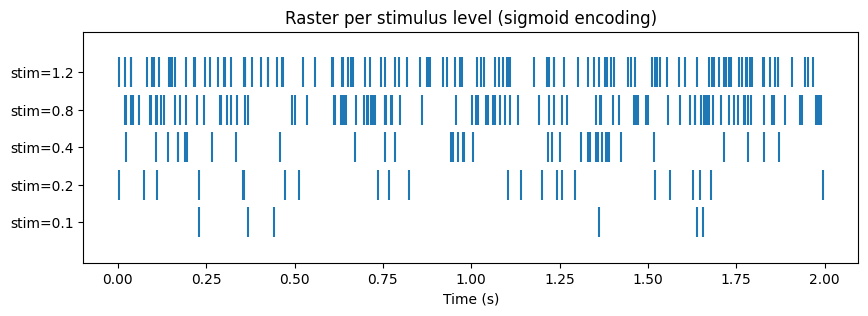

In [6]:
# TODO 3:
# Modify the encoding model: make it nonlinear (e.g., sigmoid or saturation).
# Add noise to stimulus and check stability of rate estimation.

def sigmoid_encoding(stim, r_max=60, k=6, s0=0.5):
    """Nonlinear (sigmoid / saturating) encoding: stimulus -> firing rate."""
    return r_max / (1 + np.exp(-k * (stim - s0)))

stim_fine = np.linspace(0, 1.5, 100)

# --- Nonlinear encoding without noise ---
rates_nl = sigmoid_encoding(stim_levels)
estimated_nl = []
for r in rates_nl:
    sp = poisson_spikes(r, t, dt)
    estimated_nl.append(sp.sum() / T)

# --- Nonlinear encoding WITH stimulus noise (many trials to check stability) ---
noise_std = 0.15
n_trials = 20
estimated_noisy = np.zeros((n_trials, len(stim_levels)))
for tr in range(n_trials):
    noisy_stim = stim_levels + np.random.normal(0, noise_std, size=len(stim_levels))
    r_noisy = sigmoid_encoding(noisy_stim)
    for j, r in enumerate(r_noisy):
        sp = poisson_spikes(max(r, 0), t, dt)
        estimated_noisy[tr, j] = sp.sum() / T

plt.figure(figsize=(8, 5))
plt.plot(stim_fine, sigmoid_encoding(stim_fine), "k-", label="Sigmoid encoding model")
plt.plot(stim_levels, estimated_nl, "o-", label="Estimated (no noise)")
plt.errorbar(stim_levels, estimated_noisy.mean(axis=0),
             yerr=estimated_noisy.std(axis=0), fmt="s--", capsize=4,
             label=f"Estimated (stim noise sd={noise_std}, mean±sd of {n_trials} trials)")
plt.xlabel("Stimulus level (a.u.)")
plt.ylabel("Firing rate (Hz)")
plt.title("Nonlinear (sigmoid) rate coding with and without stimulus noise")
plt.legend()
plt.show()

# --- Raster plots for the nonlinear model at each stimulus level ---
plt.figure(figsize=(10, 3))
for j, s in enumerate(stim_levels):
    sp = poisson_spikes(sigmoid_encoding(s), t, dt)
    plt.eventplot(t[sp == 1], lineoffsets=j, linelengths=0.8)
plt.yticks(range(len(stim_levels)), [f"stim={s}" for s in stim_levels])
plt.xlabel("Time (s)")
plt.title("Raster per stimulus level (sigmoid encoding)")
plt.show()

**Explanation (TODO 3, 1–2 sentences):** With the sigmoid model the raster density no longer grows linearly with the stimulus — it changes steeply near the mid-point (s ≈ 0.5) and saturates at high stimulus levels, so the two strongest stimuli produce almost identical spike densities. Adding stimulus noise makes the rate estimate unstable (large error bars), especially on the steep part of the sigmoid where small stimulus fluctuations cause big rate changes, while estimates in the saturated region remain comparatively stable.

### Part D — Timing code (precision/jitter matters)
Goal: Show that information can be carried by precise spike timing, not just counts.

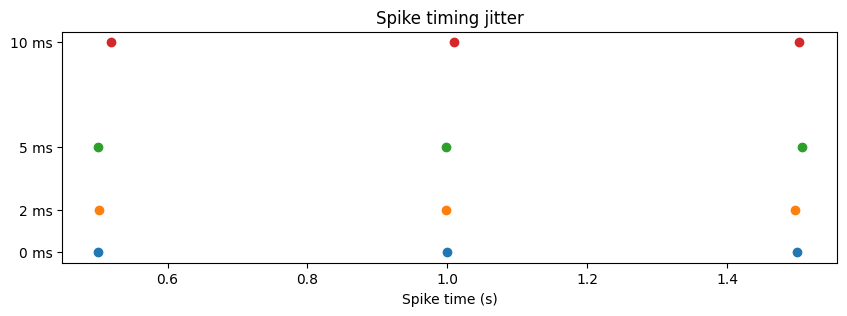

In [7]:
def jitter_spike_times(spike_times, jitter_std, rng=np.random):
    return spike_times + rng.normal(0, jitter_std, size=len(spike_times))

true_times = np.array([0.5, 1.0, 1.5])  # “coded” event times
jitters = [0.0, 0.002, 0.005, 0.01]      # 0–10 ms jitter

plt.figure(figsize=(10,3))
for j in jitters:
    obs = jitter_spike_times(true_times, j)
    plt.plot(obs, np.ones_like(obs)*j, 'o')
plt.yticks(jitters, [f"{int(j*1000)} ms" for j in jitters])
plt.xlabel("Spike time (s)")
plt.title("Spike timing jitter")
plt.show()

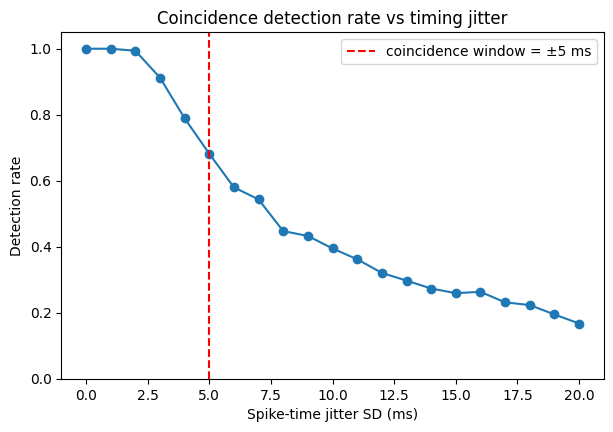

jitter =    0 ms -> detection rate = 1.000
jitter =    2 ms -> detection rate = 0.987
jitter =    5 ms -> detection rate = 0.673
jitter =   10 ms -> detection rate = 0.383
jitter =   20 ms -> detection rate = 0.184


In [8]:
# TODO 4:
# Implement a coincidence detector: count how often spikes fall within a window of a target time.
# Plot detection rate vs jitter.

def coincidence_detector(spike_times, target_times, window=0.005):
    """Fraction of target times that have >= 1 spike within +/- window."""
    detected = 0
    for tt in target_times:
        if np.any(np.abs(spike_times - tt) <= window):
            detected += 1
    return detected / len(target_times)

window = 0.005                       # +/- 5 ms coincidence window
jitter_values = np.linspace(0, 0.02, 21)   # 0 to 20 ms of jitter
n_trials = 500

detection_rates = []
for j in jitter_values:
    det = [coincidence_detector(jitter_spike_times(true_times, j),
                                true_times, window)
           for _ in range(n_trials)]
    detection_rates.append(np.mean(det))

plt.figure(figsize=(7, 4.5))
plt.plot(jitter_values * 1000, detection_rates, "o-")
plt.axvline(window * 1000, color="r", ls="--",
            label=f"coincidence window = ±{window*1000:.0f} ms")
plt.xlabel("Spike-time jitter SD (ms)")
plt.ylabel("Detection rate")
plt.title("Coincidence detection rate vs timing jitter")
plt.ylim(0, 1.05)
plt.legend()
plt.show()

for j in [0.0, 0.002, 0.005, 0.01, 0.02]:
    det = np.mean([coincidence_detector(jitter_spike_times(true_times, j),
                                        true_times, window)
                   for _ in range(n_trials)])
    print(f"jitter = {j*1000:4.0f} ms -> detection rate = {det:.3f}")

**Observation (TODO 4):** With zero jitter every spike lands inside the ±5 ms window, so detection is perfect. As jitter grows beyond the window size, spikes increasingly miss the window and the detection rate falls steeply — showing that a timing code only works when spike times are precise relative to the read-out (coincidence) window.

### Part E — Population coding + simple decoding
Goal: Show that populations reduce noise and enable decoding.

#### Baseline (run): We simulate two stimuli A and B that produce different population rates.

In [9]:
def simulate_population(stim, N=30, T=1.0, dt=0.001):
    t = np.arange(0, T, dt)
    # different rate patterns across neurons
    if stim == "A":
        rates = np.linspace(5, 25, N)
    else:
        rates = np.linspace(25, 5, N)
    spikes = np.array([poisson_spikes(r, t, dt) for r in rates])
    features = spikes.sum(axis=1) / T  # firing rate per neuron (Hz)
    return features

# dataset
X = []
y = []
for _ in range(200):
    X.append(simulate_population("A"))
    y.append(0)
    X.append(simulate_population("B"))
    y.append(1)

X = np.array(X)
y = np.array(y)

# simple linear decoder (no sklearn)
w = X[y==1].mean(axis=0) - X[y==0].mean(axis=0)
b = -0.5 * (X[y==1].mean(axis=0) + X[y==0].mean(axis=0)) @ w

pred = ((X @ w + b) > 0).astype(int)
acc = (pred == y).mean()
print("Decoding accuracy:", acc)

Decoding accuracy: 1.0


N =  5 | accuracy (independent noise) = 0.807 | accuracy (shared noise) = 0.780
N = 10 | accuracy (independent noise) = 0.863 | accuracy (shared noise) = 0.867
N = 20 | accuracy (independent noise) = 0.953 | accuracy (shared noise) = 0.887
N = 50 | accuracy (independent noise) = 0.993 | accuracy (shared noise) = 0.943


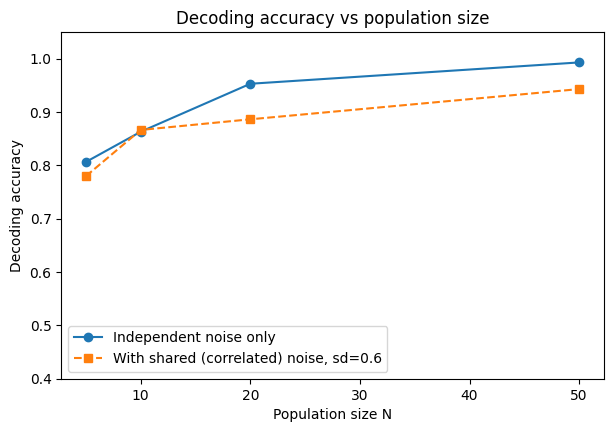

In [10]:
# TODO 5:
# Vary population size N: test N = 5, 10, 20, 50 and plot accuracy vs N.
# Add shared noise (correlation) and observe decoding accuracy drop.

def simulate_population_noisy(stim, N=30, T=0.2, dt=0.001, shared_noise_sd=0.0):
    """Population responses in a short (200 ms) window, so single neurons
    are noisy and population averaging matters.

    shared_noise_sd adds a COMMON (correlated) gain fluctuation to the
    stimulus-dependent part of every neuron's rate in the trial — the same
    random fluctuation hits all neurons at once, so it cannot be averaged out.
    """
    t_loc = np.arange(0, T, dt)
    if stim == "A":
        rates = np.linspace(10, 20, N)
    else:
        rates = np.linspace(20, 10, N)
    mean_rate = rates.mean()
    gain = 1.0 + np.random.normal(0, shared_noise_sd)  # shared across ALL neurons
    rates = np.clip(mean_rate + gain * (rates - mean_rate), 0, None)
    spikes = np.array([poisson_spikes(r, t_loc, dt) for r in rates])
    return spikes.sum(axis=1) / T

def decoding_accuracy(N, shared_noise_sd=0.0, n_trials_per_class=150):
    X, y = [], []
    for _ in range(n_trials_per_class):
        X.append(simulate_population_noisy("A", N=N, shared_noise_sd=shared_noise_sd)); y.append(0)
        X.append(simulate_population_noisy("B", N=N, shared_noise_sd=shared_noise_sd)); y.append(1)
    X, y = np.array(X), np.array(y)
    w = X[y == 1].mean(axis=0) - X[y == 0].mean(axis=0)
    b = -0.5 * (X[y == 1].mean(axis=0) + X[y == 0].mean(axis=0)) @ w
    pred = ((X @ w + b) > 0).astype(int)
    return (pred == y).mean()

N_values = [5, 10, 20, 50]

acc_indep = [decoding_accuracy(N, shared_noise_sd=0.0) for N in N_values]
acc_shared = [decoding_accuracy(N, shared_noise_sd=0.6) for N in N_values]

for N, a0, a1 in zip(N_values, acc_indep, acc_shared):
    print(f"N = {N:2d} | accuracy (independent noise) = {a0:.3f} | "
          f"accuracy (shared noise) = {a1:.3f}")

plt.figure(figsize=(7, 4.5))
plt.plot(N_values, acc_indep, "o-", label="Independent noise only")
plt.plot(N_values, acc_shared, "s--", label="With shared (correlated) noise, sd=0.6")
plt.xlabel("Population size N")
plt.ylabel("Decoding accuracy")
plt.title("Decoding accuracy vs population size")
plt.ylim(0.4, 1.05)
plt.legend()
plt.show()

**Observation (TODO 5):** With only independent Poisson noise, decoding accuracy improves steadily with population size (roughly 0.81 at N=5 up to ~0.99 at N=50), because averaging across neurons cancels independent variability (noise shrinks like 1/√N). With shared (correlated) noise added, accuracy stays lower at large N and never reaches the independent-noise level — the correlated fluctuation hits all neurons the same way, so adding more neurons cannot average it out.

#### Writing questions.

1. Rate coding vs timing coding (2–3 sentences)

2. What refractory changes

3. How population size affects decoding

#### Answers to the writing questions

**1. Rate coding vs timing coding.**
In rate coding, information is carried by the *number* of spikes fired per unit time (the firing rate), so the exact spike times do not matter — e.g. stimulus intensity mapped to firing rate in Part C. In temporal (timing) coding, information is carried by the *precise timing* of individual spikes relative to a reference or to other neurons, as in Part D, so even small timing jitter can destroy the message. Rate codes are robust but slow (they need a time window to count spikes), while timing codes are fast and higher-capacity but require millisecond precision.

**2. What the refractory period changes.**
The refractory period is the short interval after a spike during which the neuron cannot fire again. It imposes a hard upper limit on the firing rate (roughly 1/refrac_s), removes short inter-spike intervals — creating the "gap" at the left of the ISI distribution — and makes the spike train more regular than a pure Poisson process. As the refractory period increases, the achieved firing rate falls further below the nominal rate and the ISI gap widens.

**3. How population size affects decoding.**
Because each neuron's spiking is noisy, a decoder that reads many neurons can average out independent noise, so decoding accuracy improves rapidly as population size N grows (variability of the population average falls like 1/√N). However, this benefit holds only for independent noise: when neurons share correlated noise, the shared fluctuations cannot be averaged away, so accuracy saturates or drops even for large populations.